# Ejercicio 1 — Campañas de marketing con creadores de contenido

## Índice

**1.1 Exploración y representación**

1. [Problema y objetivo](#1.-Problema-y-objetivo)
2. [Datos y selección de variables](#2.-Datos-y-selección-de-variables)
3. [Análisis exploratorio](#3.-Análisis-exploratorio)
4. [PCA](#4.-PCA)
5. [Conclusiones del 1.1](#5.-Conclusiones-del-1.1)

**1.2 Red de Kohonen**

6. [Implementación](#6.-Implementación)
7. [Selección de hiperparámetros](#7.-Selección-de-hiperparámetros)
8. [Grilla de neuronas y matriz U](#8.-Grilla-de-neuronas-y-matriz-U)
9. [Interpretación de las regiones](#9.-Interpretación-de-las-regiones)
10. [Conclusiones del 1.2](#10.-Conclusiones-del-1.2)

**1.3 Índice con la regla de Oja**

11. [Implementación y convergencia](#11.-Implementación-y-convergencia)
12. [Comparación con PC1](#12.-Comparación-con-PC1)
13. [Interpretación del índice](#13.-Interpretación-del-índice)
14. [Conclusiones del 1.3](#14.-Conclusiones-del-1.3)

**1.4 Decisión para las campañas**

15. [Supuestos y métrica de campaña](#15.-Supuestos-y-métrica-de-campaña)
16. [Campaña de fútbol](#16.-Campaña-de-fútbol)
17. [Selección propuesta frente a la selección por seguidores](#17.-Selección-propuesta-frente-a-la-selección-por-seguidores)
18. [Mantenimiento del sistema](#18.-Mantenimiento-del-sistema)
19. [Conclusiones generales](#19.-Conclusiones-generales)

## 1. Problema y objetivo

La agencia elige creadores por cantidad de seguidores y sus campañas no recuperan la inversión. Cada cliente (refugios de perros, ropa de fútbol, belleza y materiales de arte) necesita una audiencia y un contenido distintos.

**Hipótesis de trabajo:** elegir por seguidores equivale a quedarse con un solo eje de los datos, el que va de lo masivo a lo profundo. Lo que distingue a cada cliente, la temática y la audiencia local, está en otras direcciones. El trabajo pone a prueba esa idea en cuatro pasos:

- **1.1 Exploración y PCA:** qué variables describen a un creador y qué ejes tiene el catálogo.
- **1.2 Kohonen:** qué grupos de creadores aparecen usando todas las variables.
- **1.3 Oja:** un índice de una sola dimensión, y si sirve para elegir.
- **1.4 Decisión:** cómo combinar lo anterior para elegir creadores para cada cliente.

El código está en módulos: `preprocessing.py` (selección y estandarización, que reutilizan Kohonen y Oja), `eda.py`, `pca.py` (PCA propio con numpy), `kohonen.py` (red de Kohonen propia), `oja.py` (regla de Oja propia), `campaigns.py` (selección por campaña) y `plots.py`.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Permite ejecutar el notebook tanto desde la raíz del repositorio como desde TP4.
cwd = Path.cwd()
tp4_dir = cwd / "TP4" if (cwd / "TP4" / "pca.py").exists() else cwd
if str(tp4_dir) not in sys.path:
    sys.path.insert(0, str(tp4_dir))

import eda
import plots
from pca import PCA, broken_stick, retention_criteria
from preprocessing import (FEATURE_GROUPS, check_derived, composition_sums, find_data_path,
                           load_creators, prepare_features)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", None)
plots.set_style()

DATA_PATH = find_data_path()
df = load_creators(DATA_PATH)
df.head()

,creator_id,name,followers,average_reach,average_impressions,average_video_views,monthly_posts,argentina_audience_pct,estimated_argentina_reach,non_follower_reach_pct,...,topic_art_pct,content_tutorial_pct,content_review_pct,content_entertainment_pct,content_showcase_pct,average_caption_words,average_watch_time_seconds,video_posts_pct,short_form_posts_pct,trend_posts_pct
0,INF001,@mateconideas,775589,245722,369678,176505,26,83.190,204416,55.950,...,15.300,2.780,13.730,68.360,15.130,56.190,18.850,58.430,60.030,49.200
1,INF002,@brillourbano,638718,235620,281643,180650,15,29.780,70168,77.770,...,6.930,9.920,10.890,69.300,9.890,54.050,20.760,66.490,70.470,54.140
2,INF003,@huellasyconsejos,13235,4193,6339,2378,10,94.430,3959,30.100,...,15.290,59.480,27.540,0.380,12.600,180.740,31.070,24.950,21.890,13.050
3,INF004,@pincelcotidiano,333692,98820,155470,78156,15,42.100,41603,80.570,...,70.190,24.830,24.010,11.130,40.030,66.940,19.080,66.010,72.680,56.460
4,INF005,@tribunacreativa,461892,178805,210636,138941,7,68.300,122124,82.100,...,10.440,8.250,2.840,85.910,3.000,50.880,20.940,66.840,66.690,54.030


## 2. Datos y selección de variables

In [2]:
print(f"Creadores: {len(df)} | columnas: {df.shape[1]}")
print(f"Valores faltantes: {int(df.isna().sum().sum())} | filas duplicadas: {int(df.duplicated().sum())}")
display(check_derived(df))
display(composition_sums(df))

Creadores: 50 | columnas: 33
Valores faltantes: 0 | filas duplicadas: 0


,fórmula,error máx.,error relativo máx.
columna,,,
price_ars,price_usd · 1500,0.000,0.000
estimated_argentina_reach,average_reach · argentina_audience_pct / 100,0.499,0.000
total_engagement_per_1000,likes + comments + saves + shares (por 1000),0.000,0.000
organic_posts_pct,100 − sponsored_posts_pct,0.000,0.000


,min,max
topic_*,100.000,100.000
content_*,100.000,100.000
sponsored + organic,100.000,100.000


No hay faltantes ni duplicados. Las cuatro columnas derivadas cumplen su fórmula (`estimated_argentina_reach` difiere en menos de 0,5 cuentas por redondeo), y `topic_*`, `content_*` y `sponsored`/`organic` suman exactamente 100.

| Decisión | Variables | Motivo |
|---|---|---|
| Se excluyen | `creator_id`, `name` | Identificadores. |
| Se excluyen | `price_ars`, `organic_posts_pct`, `total_engagement_per_1000`, `estimated_argentina_reach` | Son fórmulas exactas de otras variables que ya están. |
| Se conservan | las cuatro `topic_*` y las cuatro `content_*` | Cada temática es un cliente. Aunque cada grupo suma 100, para PCA eso sólo produce un autovalor nulo. |

Quedan **27 variables**. Las cinco de escala (`followers`, `average_reach`, `average_impressions`, `average_video_views`, `price_usd`) se pasan a **log10**, y luego todas se estandarizan.

In [3]:
data = prepare_features(df)
features = data.features
raw = df[features]

for group, columns in FEATURE_GROUPS.items():
    print(f"{group:<18} ({len(columns)}): {', '.join(columns)}")

Alcance y precio   (7): followers, average_reach, average_impressions, average_video_views, price_usd, monthly_posts, non_follower_reach_pct
Audiencia          (1): argentina_audience_pct
Interacción        (5): likes_per_1000, comments_per_1000, saves_per_1000, shares_per_1000, profile_visits_per_1000
Comercial          (1): sponsored_posts_pct
Temática           (4): topic_football_pct, topic_makeup_pct, topic_dogs_pct, topic_art_pct
Tipo de contenido  (4): content_tutorial_pct, content_review_pct, content_entertainment_pct, content_showcase_pct
Formato            (5): average_caption_words, average_watch_time_seconds, video_posts_pct, short_form_posts_pct, trend_posts_pct


## 3. Análisis exploratorio

,media,desvío,min,mediana,max,cv,asimetría,curtosis
followers,"221,587.140","208,330.810","9,604.000","198,476.000","775,589.000",0.940,0.985,0.191
average_reach,"81,608.760","81,654.621","2,786.000","54,935.500","268,518.000",1.001,0.991,-0.225
average_impressions,"114,068.400","112,361.856","3,585.000","81,609.500","369,678.000",0.985,0.965,-0.186
average_video_views,"61,207.460","63,364.196","1,719.000","41,113.500","206,530.000",1.035,0.990,-0.304
price_usd,"1,700.803","1,728.144",75.000,"1,061.565","6,334.710",1.016,1.205,0.625
monthly_posts,15.760,6.416,5.000,15.000,28.000,0.407,0.227,-0.887
non_follower_reach_pct,55.629,17.757,19.330,56.220,82.100,0.319,-0.253,-0.943
argentina_audience_pct,52.644,22.320,19.550,48.580,94.430,0.424,0.313,-1.256
likes_per_1000,42.569,6.906,22.280,43.455,55.100,0.162,-0.807,0.819
comments_per_1000,4.460,1.405,0.790,4.350,7.280,0.315,-0.072,0.043


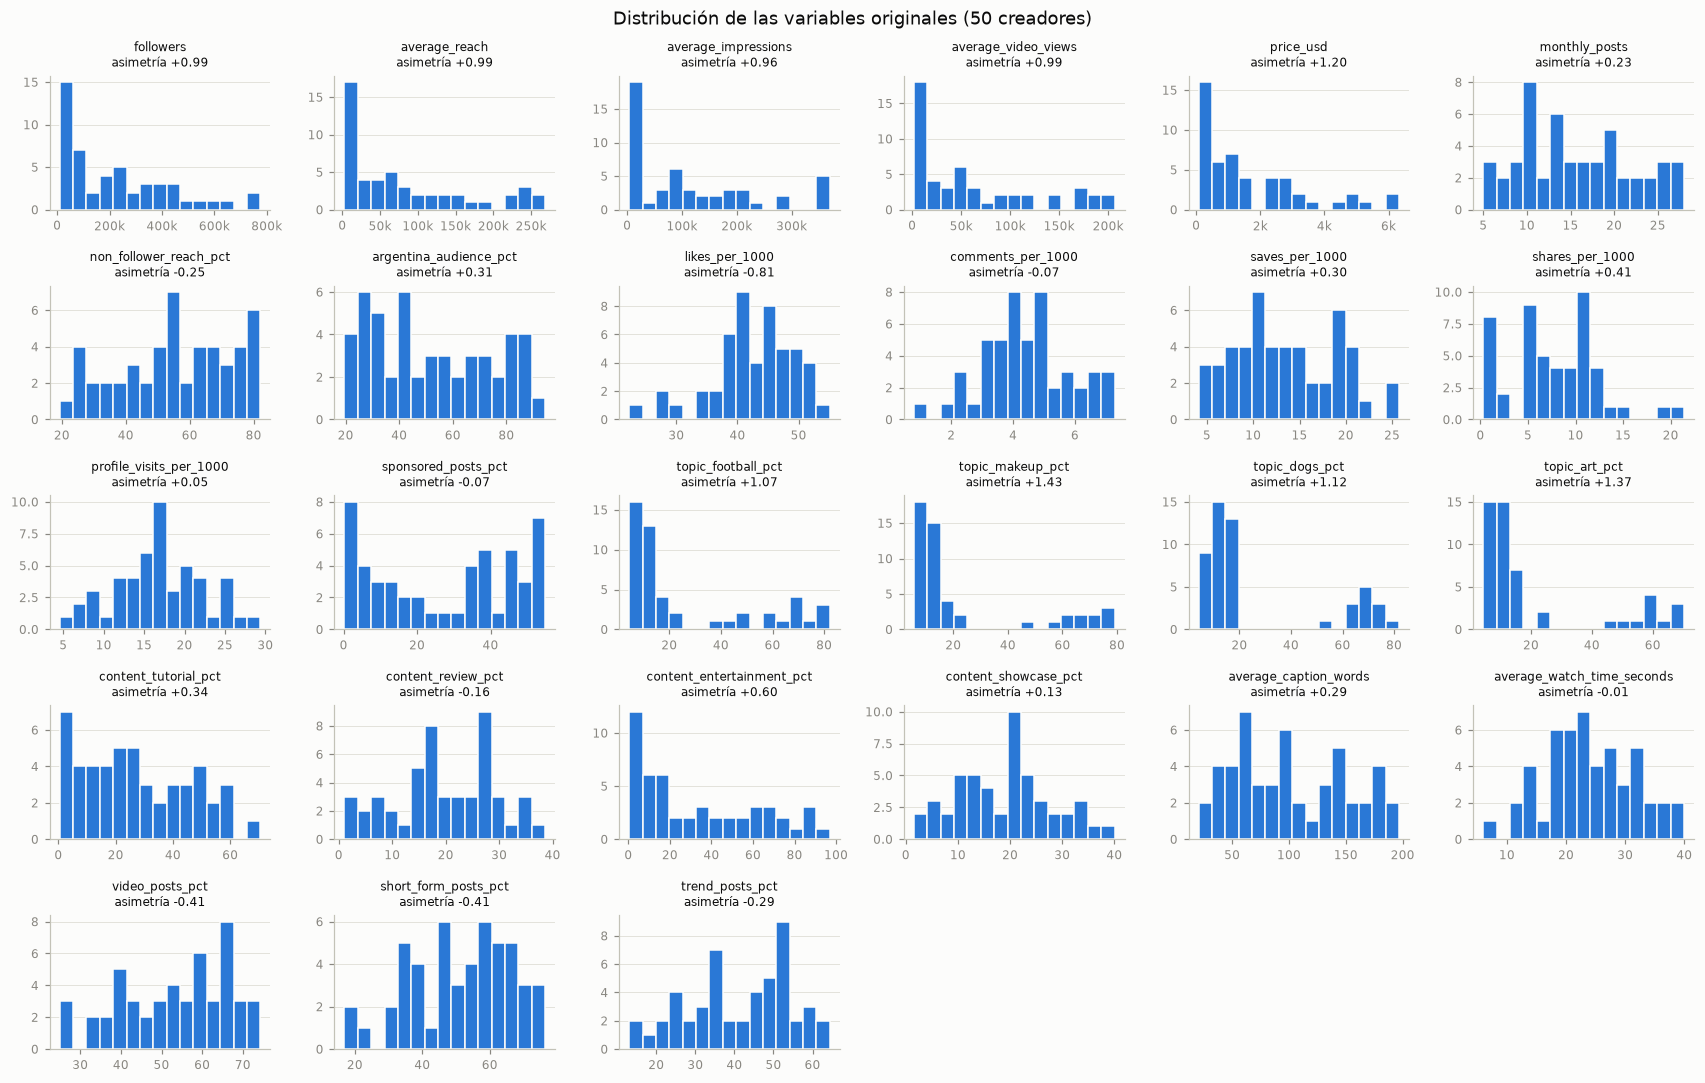

In [4]:
display(eda.describe(raw))
plots.plot_distributions(raw)
plt.show()

- **Escalas muy distintas.** `followers` llega a ~775.000 y `comments_per_1000` no pasa de 7. Por eso se estandariza y el PCA se hace sobre la matriz de correlación.
- **Variables de escala con cola a derecha.** Son conteos y precios que abarcan dos órdenes de magnitud y cuyas diferencias son multiplicativas. Con log10 la asimetría baja de ≈ +1 a ≈ −0,35, y unos pocos creadores masivos dejan de concentrar la varianza.
- **Temáticas bimodales.** Cada creador tiene una temática dominante (≈ 65 % de sus publicaciones). Por eso la regla 1,5·IQR marca como "atípicos" a los 11 especialistas en maquillaje y a los 11 en arte. Es estructura de los datos, no error: **no se descarta ningún creador**.

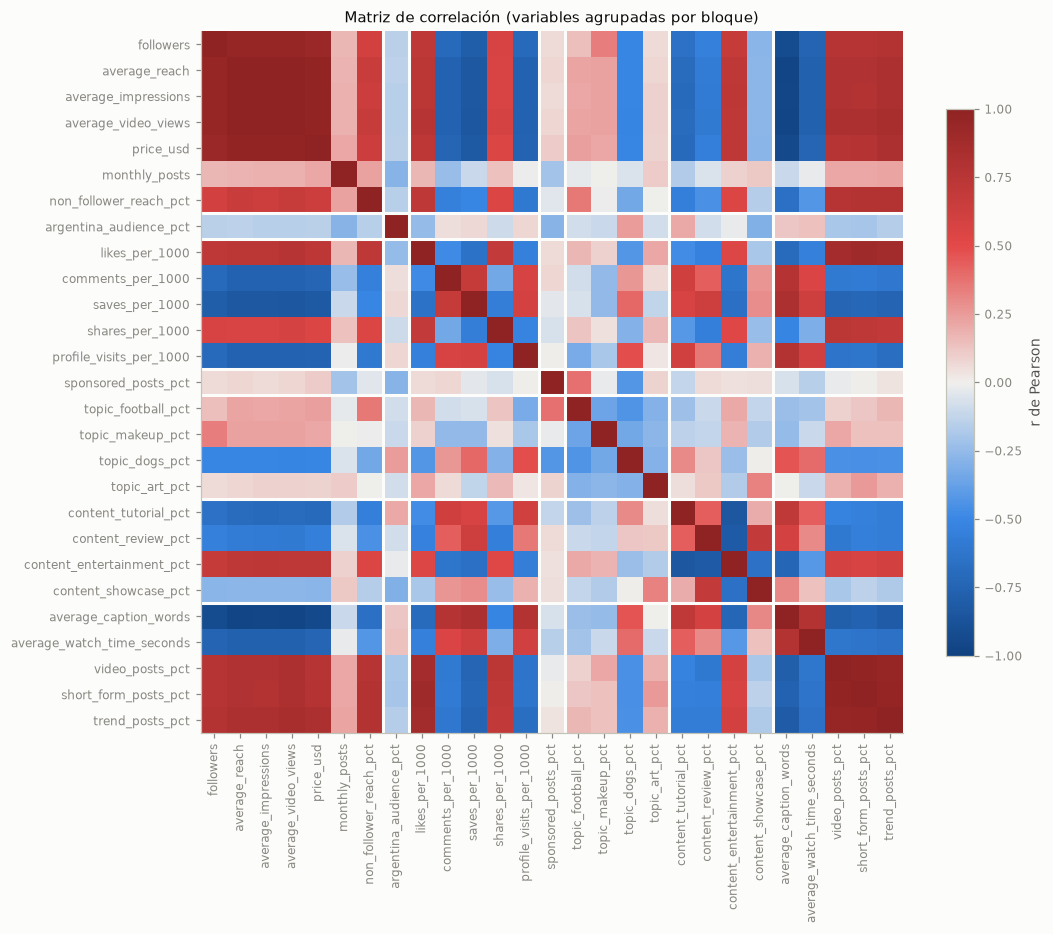

,variable 1,variable 2,r
0,average_reach,average_video_views,0.997
1,average_impressions,average_video_views,0.988
2,average_reach,average_impressions,0.987
3,video_posts_pct,short_form_posts_pct,0.971
4,short_form_posts_pct,trend_posts_pct,0.961
5,video_posts_pct,trend_posts_pct,0.952
6,followers,average_reach,0.918
7,average_impressions,price_usd,0.915
8,followers,average_impressions,0.912
9,average_video_views,price_usd,0.908


In [5]:
plots.plot_correlation(data.transformed, FEATURE_GROUPS)
plt.show()
display(eda.correlated_pairs(raw, threshold=0.9))

- **Bloques casi redundantes:** `average_reach`, `average_impressions` y `average_video_views` tienen r > 0,98 entre sí, y con `followers` y `price_usd` r > 0,9. Lo mismo pasa con `video_posts_pct`, `short_form_posts_pct` y `trend_posts_pct` (r > 0,95).
- **Dos perfiles opuestos (patrón de tablero):** tamaño, formato corto, likes y entretenimiento por un lado; guardados, comentarios, visitas al perfil, textos largos y tutoriales por el otro.

Las variables redundantes se dejan a propósito: que PCA las agrupe es lo que justifica la reducción.

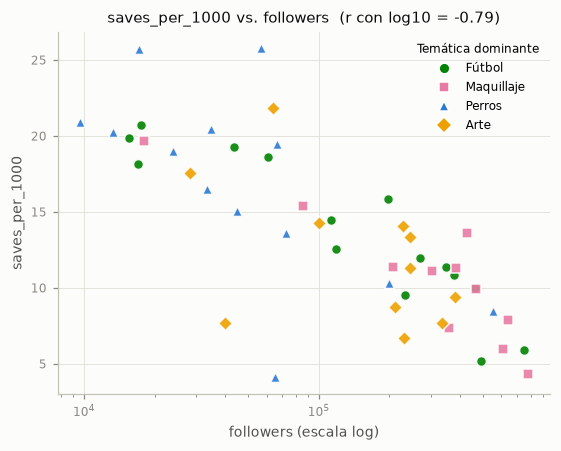

In [6]:
plots.plot_reach_vs_depth(df, data.topic, ["saves_per_1000"])
plt.show()

**A más seguidores, menos guardados por cada 1000 cuentas alcanzadas.** Elegir sólo por `followers` selecciona audiencias que miran pero no se involucran. Además, en cada temática hay creadores grandes y chicos: tamaño y temática son ejes distintos.

## 4. PCA

`pca.PCA` descompone la matriz de correlación $C = \frac{1}{n} Z^\top Z$ con `np.linalg.eigh`. Las componentes son los autovectores ordenados por autovalor, los scores son $ZV$ y las cargas son $V\sqrt{\Lambda}$ (la correlación entre cada variable y cada componente). Se valida contra sklearn.

Máx. diferencia en varianza explicada vs. sklearn: 1.1e-16
Últimos autovalores: [0.003  0.0002 0.     0.    ]


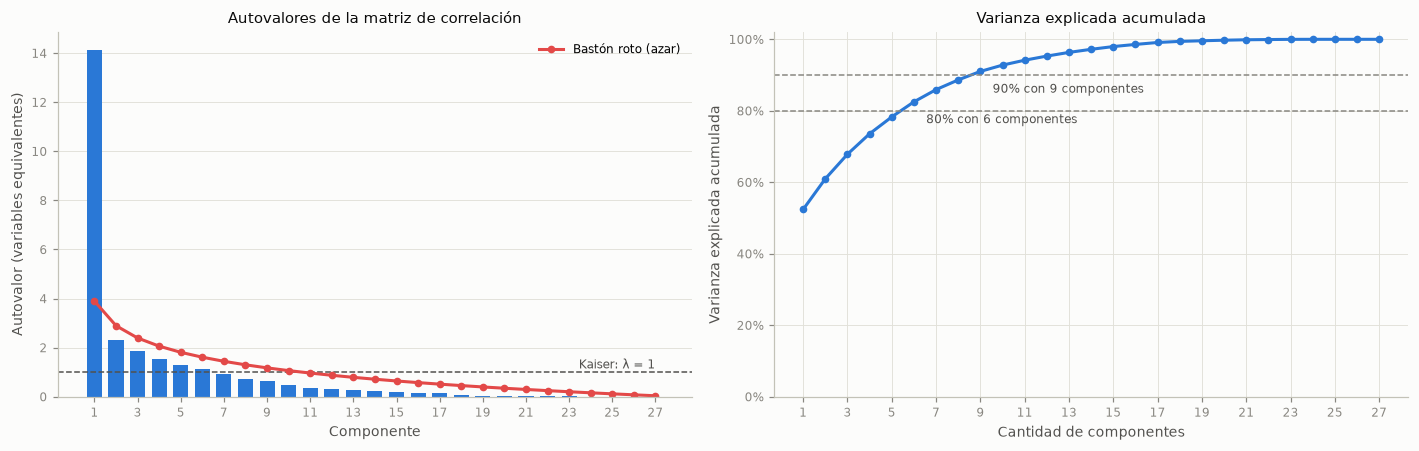

,componentes
Kaiser (λ > 1),6
Bastón roto,1
Varianza acumulada ≥ 80%,6
Varianza acumulada ≥ 90%,9


In [7]:
X = data.X
pca = PCA().fit(X)
scores = pca.transform(X)
eigenvalues = pca.eigenvalues_
explained = pca.explained_variance_ratio_

from sklearn.decomposition import PCA as SklearnPCA

reference = SklearnPCA().fit(X)
print(f"Máx. diferencia en varianza explicada vs. sklearn: {np.abs(reference.explained_variance_ratio_ - explained).max():.1e}")
print(f"Últimos autovalores: {np.round(eigenvalues[-4:], 4)}")

plots.plot_scree(eigenvalues, broken_stick(len(eigenvalues)))
plt.show()
display(retention_criteria(eigenvalues).to_frame())

- Los dos últimos autovalores son **0** (las restricciones "`topic_*` suma 100" y "`content_*` suma 100") y los dos anteriores son **casi 0** (reach, impressions y views son prácticamente la misma variable). El espectro confirma las redundancias del EDA.
- **PC1 sola explica ≈ 52 %** (resume el equivalente a 14 de las 27 variables), y después hay una caída abrupta.
- **Kaiser** y **80 % acumulado** coinciden en **6 componentes** (≈ 82 %). El bastón roto sólo confirma PC1. Con 50 creadores, PC2–PC6 son interpretables pero menos estables.

**La reducción está justificada para interpretar el catálogo:** con 6 componentes de 27 variables se conserva ≈ 82 % de la varianza, y las 4 primeras tienen lectura de negocio. No se usa como entrada de Kohonen ni de Oja, porque el enunciado pide agrupar "en términos de todas sus variables". Las componentes sirven de referencia para leer el mapa y el índice.

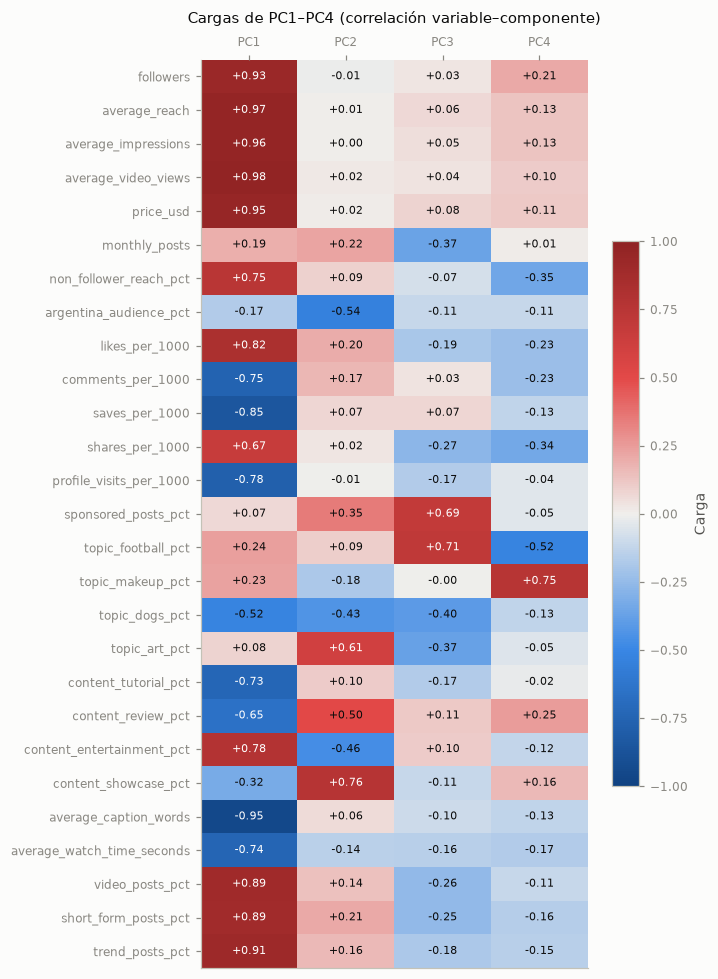

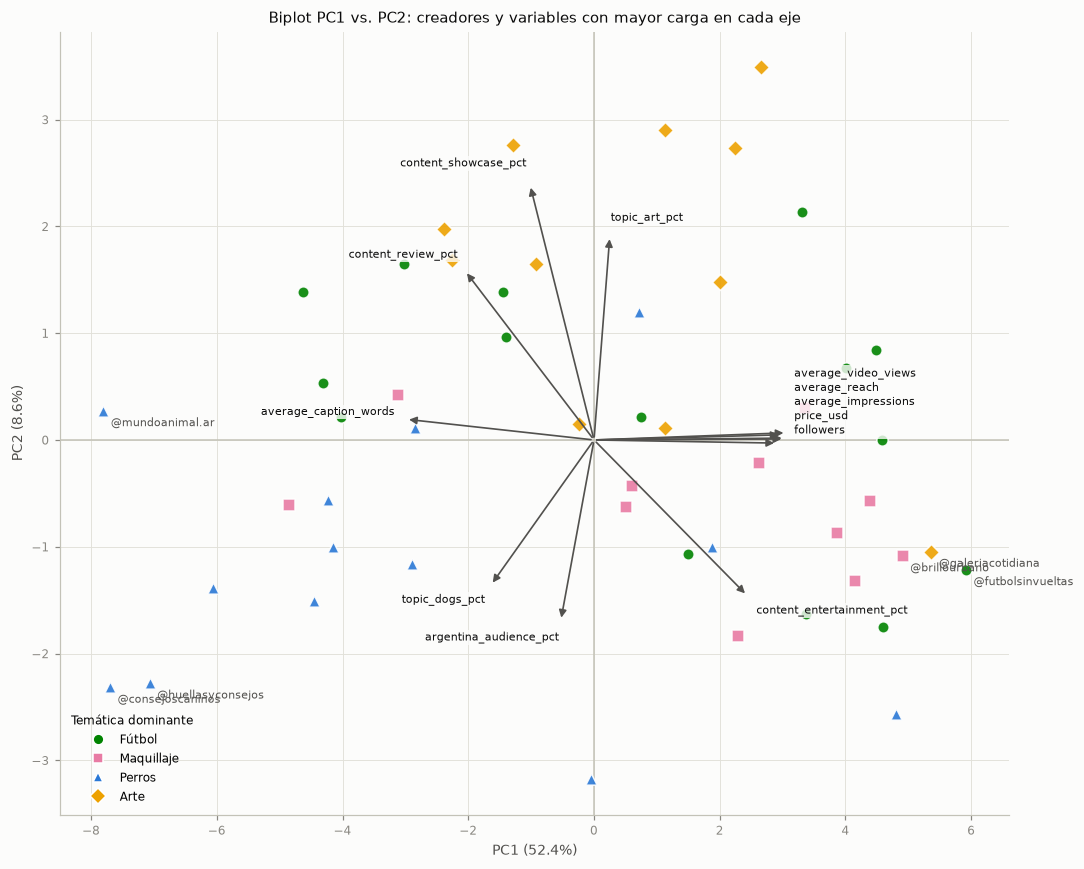

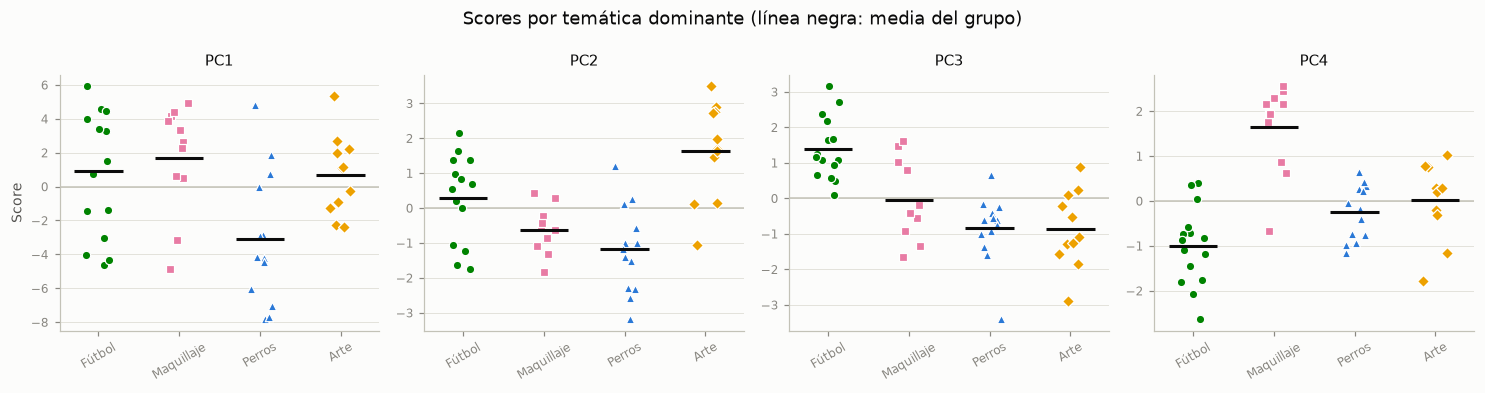

Correlación de PC1 con log10(followers): +0.928


In [8]:
loadings = pca.loadings(features)
plots.plot_annotated_heatmap(loadings.iloc[:, :4], "Cargas de PC1–PC4 (correlación variable–componente)",
                             "Carga", limit=1, figsize=(6.5, 9))
plt.show()
plots.plot_biplot(scores, loadings, data.topic, data.names, pcs=(1, 2), explained=explained)
plt.show()
plots.plot_scores_by_topic(scores, data.topic, n_components=4)
plt.show()
print(f"Correlación de PC1 con log10(followers): {np.corrcoef(scores[:, 0], data.transformed['followers'])[0, 1]:+.3f}")

| Componente | Varianza | Polo positivo | Polo negativo | Lectura |
|---|---|---|---|---|
| **PC1** | 52 % | reach, views, impressions, precio, followers (> 0,9), formato corto, entretenimiento, likes | palabras del texto (−0,95), guardados, visitas al perfil, comentarios, tutoriales | **Alcance masivo ↔ profundidad** |
| **PC2** | 9 % | showcase, arte, reseñas | audiencia argentina, entretenimiento, perros | Separa **arte** |
| **PC3** | 7 % | fútbol, patrocinio | perros, arte, frecuencia | Separa **fútbol** |
| **PC4** | 6 % | maquillaje | fútbol | Separa **maquillaje** |

- PC1 correlaciona 0,93 con log10(followers): **la estrategia actual equivale a ordenar por PC1**, e ignora que el polo opuesto concentra el engagement de mayor intención.
- En los scores por temática, **PC1 tiene mucha dispersión dentro de cada temática** (perros se concentra en el polo profundo), mientras que **las temáticas se separan en PC2–PC4**. Elegir creador implica dos decisiones independientes: temática y tipo de alcance.

## 5. Conclusiones del 1.1

- **Variables:** 27, sin los identificadores ni las 4 columnas derivadas, con log10 en las 5 de escala y estandarizadas. Kohonen y Oja usan el mismo preprocesamiento.
- **Ejes:** PC1 (masivo ↔ profundo, 52 %) es casi log10(followers). PC2, PC3 y PC4 separan arte, fútbol y maquillaje.
- **Limitación que se arrastra:** las 5 variables de tamaño son casi la misma y pesan de más en la distancia de Kohonen y en la dirección que aprende Oja. Las partes siguientes la tienen en cuenta.

## 6. Implementación

`kohonen.Kohonen` implementa un mapa autoorganizado sobre una grilla rectangular de `filas × columnas` neuronas. Cada neurona tiene un vector de pesos (su **prototipo**) en el mismo espacio que los creadores: las 27 variables estandarizadas del 1.1.

1. **Inicialización:** cada prototipo arranca en un creador elegido al azar.
2. **Entrenamiento online:** en cada época se recorren los 50 creadores en orden aleatorio. Para cada creador $x$ se busca la neurona ganadora (BMU), la de prototipo más cercano en distancia euclídea, y se actualizan todas las neuronas:
$$w_j \leftarrow w_j + \eta(t)\, h_j(t)\,(x - w_j), \qquad h_j(t) = \exp\!\left(-\frac{\lVert r_j - r_{\text{BMU}} \rVert^2}{2R(t)^2}\right)$$
   donde $r_j$ es la posición de la neurona en la grilla. La tasa $\eta$ decae exponencialmente de $\eta_0$ a 0,01 y el radio $R$ de $R_0$ a $R_{\text{final}}$.
3. **Métricas:**
   - **Error de cuantización (QE):** distancia media de cada creador a su prototipo. Mide qué tan bien los prototipos representan a los creadores.
   - **Error topográfico (TE):** fracción de creadores cuyas dos neuronas más cercanas no son vecinas en la grilla (se cuentan las 8 que la rodean). Mide si el mapa preserva la vecindad: creadores parecidos deben quedar en neuronas contiguas.
   - **Varianza explicada:** $1 - \text{QE}^2_{\text{medio}} / \text{varianza total}$. Es comparable con la varianza explicada del PCA.

In [9]:
from kohonen import Kohonen, explained_variance, sweep

configs = [{"rows": side, "cols": side, "radius": side / 2, "final_radius": final_radius}
           for side in range(3, 9) for final_radius in (1.0, 0.5, 0.2)]
grid_results = (sweep(X, configs, learning_rate=0.5, epochs=100)
                .rename(columns={"rows": "lado", "final_radius": "radio final"}))

## 7. Selección de hiperparámetros

Primero se varían los dos hiperparámetros que más cambian el resultado: el **tamaño de la grilla** (de 3×3 a 8×8) y el **radio final** de la vecindad. Cada configuración se entrena con 5 semillas, con $\eta_0 = 0{,}5$, $R_0$ igual a la mitad del lado y 100 épocas.

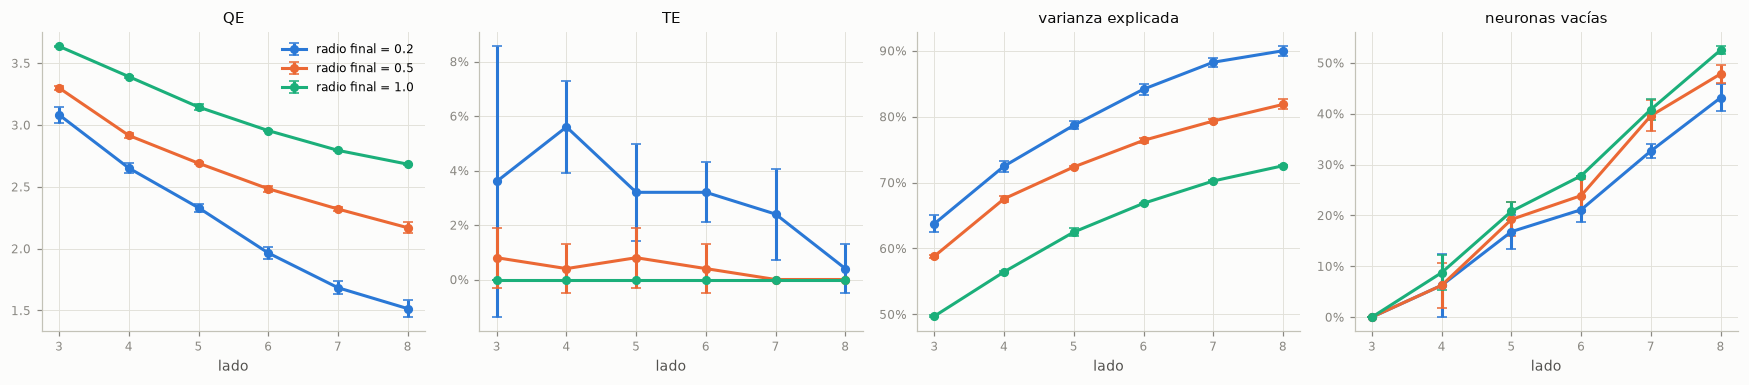

In [10]:
plots.plot_som_sweep(grid_results, x="lado", hue="radio final")
plt.show()

- **El QE no sirve para elegir el tamaño por sí solo**: baja siempre al agregar neuronas. Con 8×8 hay más neuronas (64) que creadores (50), y el mapa tiende a asignar un prototipo por creador.
- **Radio final.** Con 1,0 la vecindad sigue siendo ancha al terminar: el mapa queda rígido y representa mal a los creadores (QE alto, varianza explicada baja). Con 0,2 cada neurona se ajusta sola al final y el mapa empieza a perder orden (TE de 3 a 6 % y más variable entre semillas). **0,5** logra un TE prácticamente nulo con un QE intermedio.
- **Tamaño.** Desde 5×5 cada lado adicional suma poca varianza explicada (+3 a 4 puntos) y muchas neuronas vacías (19 % con 5×5, 24 % con 6×6, 40 % con 7×7). Con 50 creadores, **5×5** deja ≈ 2 creadores por neurona y reproduce ≈ 72 % de la varianza. Las 2 primeras componentes del PCA reproducen 61 % y las 4 primeras 74 %. Con 4×4 se mezclan más las temáticas en una misma neurona.

Con la grilla fijada en 5×5 y radio final 0,5, se varía un hiperparámetro por vez respecto de la configuración elegida:

In [11]:
BASE = {"rows": 5, "cols": 5, "learning_rate": 0.5, "radius": 2.5, "final_radius": 0.5,
        "epochs": 100, "init": "sample"}
variations = {
    "learning_rate": [0.1, 0.5, 0.9],
    "radius": [1.25, 2.5, 5.0],
    "init": ["sample", "pca"],
    "epochs": [25, 50, 100, 200, 400],
}
tables = []
for parameter, values in variations.items():
    fixed = {key: value for key, value in BASE.items() if key != parameter}
    result = sweep(X, [{parameter: value} for value in values], **fixed)
    summary = result.groupby(parameter, sort=False)[["QE", "TE", "varianza explicada"]].agg(["mean", "std"])
    summary.index = pd.MultiIndex.from_product([[parameter], summary.index.astype(str)],
                                               names=["parámetro", "valor"])
    tables.append(summary)
display(pd.concat(tables))

QE          TE       varianza explicada      
                      mean   std  mean   std               mean   std
parámetro     valor                                                  
learning_rate 0.1    2.771 0.038 0.012 0.018              0.708 0.008
              0.5    2.691 0.007 0.008 0.011              0.724 0.001
              0.9    2.669 0.020 0.004 0.009              0.728 0.005
radius        1.25   2.567 0.047 0.020 0.014              0.749 0.009
              2.5    2.691 0.007 0.008 0.011              0.724 0.001
              5.0    2.799 0.045 0.000 0.000              0.701 0.009
init          sample 2.691 0.007 0.008 0.011              0.724 0.001
              pca    2.673 0.032 0.000 0.000              0.727 0.007
epochs        25     2.902 0.033 0.012 0.018              0.680 0.006
              50     2.770 0.018 0.008 0.011              0.708 0.004
              100    2.691 0.007 0.008 0.011              0.724 0.001
              200    2.621 0.009 0.004 0.009              0.737 0.002
              400    2.552 0.021 0.004 0.009              0.750 0.006

- **Tasa de aprendizaje** ($\eta_0$): entre 0,5 y 0,9 casi no hay diferencia. Con 0,1 el mapa se acomoda más lento y el QE sube. Se usa **0,5**.
- **Radio inicial** ($R_0$): un radio más chico baja algo el QE, pero con la mitad del lado (**2,5**) cada actualización alcanza a todo el mapa al comienzo, y eso es lo que lo ordena globalmente. La diferencia es menor al 5 %.
- **Inicialización:** arrancar desde creadores al azar o desde el plano PC1–PC2 da el mismo resultado. Se usa la aleatoria, así el mapa no recibe información del PCA y la comparación con el biplot es independiente.
- **Épocas:** el QE baja poco después de 100 épocas y el TE no cambia. Se usan **100**.

**Configuración final:** grilla 5×5, $\eta_0 = 0{,}5$, $R_0 = 2{,}5$, $R_{\text{final}} = 0{,}5$, 100 épocas. Las métricas varían poco entre semillas (desvíos de QE ≈ 0,01): el mapa es estable, y con otra semilla se obtiene el mismo mapa rotado o espejado.

## 8. Grilla de neuronas y matriz U

QE = 2.686 | TE = 0% | varianza explicada = 72.4% | neuronas vacías = 4/25


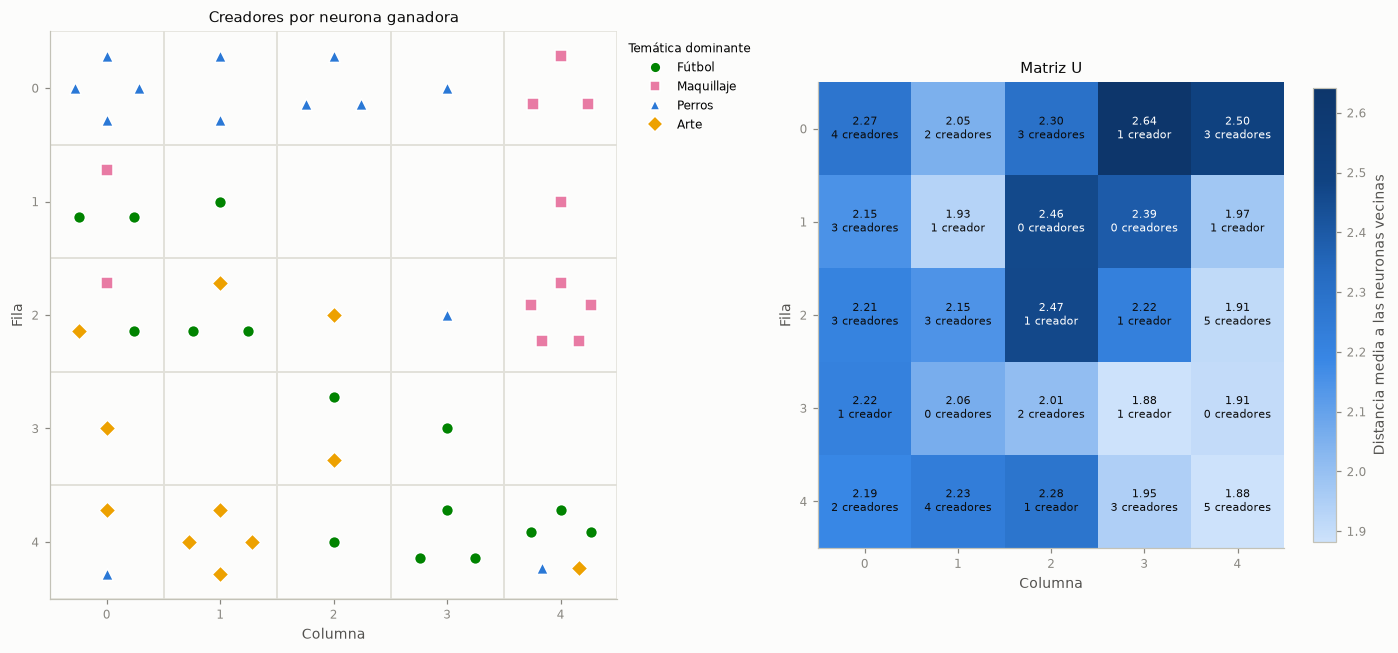

In [12]:
som = Kohonen(**BASE, seed=0).fit(X)
print(f"QE = {som.quantization_error(X):.3f} | TE = {som.topographic_error(X):.0%} | "
      f"varianza explicada = {explained_variance(som, X):.1%} | "
      f"neuronas vacías = {int((som.hits(X) == 0).sum())}/{som.n_neurons}")
plots.plot_som_maps(som, X, data.topic)
plt.show()

La **matriz U** muestra, para cada neurona, la distancia media entre su prototipo y los de sus vecinas. **Una distancia alta indica una frontera**: dos neuronas contiguas en la grilla representan creadores muy distintos, y pasar de una a otra es un cambio de perfil. Valores bajos indican zonas homogéneas, donde los creadores vecinos se parecen.

- **Distribución:** las temáticas ocupan zonas contiguas. Perros está en la fila superior, maquillaje en la columna derecha, arte abajo a la izquierda y fútbol abajo y al centro. Las mezclas aparecen sobre todo en la esquina inferior derecha.
- **Fronteras:** los valores más altos están alrededor de la fila de perros y de la columna de maquillaje, incluidas las neuronas vacías del centro, (1,2) y (1,3). Esas neuronas no representan a ningún creador: funcionan como **separadores** entre perfiles.
- **Zonas homogéneas:** la esquina inferior derecha tiene los valores más bajos. Ahí los creadores masivos se parecen entre sí aunque publiquen sobre temas distintos.
- **Contraste moderado:** U va de ≈ 1,9 a ≈ 2,6. No hay grupos aislados por saltos grandes, sino un **continuo** con sub-regiones. Es coherente con el PCA, donde sólo PC1 se destaca claramente del azar.

## 9. Interpretación de las regiones

Los **planos de componentes** muestran el valor de cada variable en el prototipo de cada neurona. Leerlos juntos permite asignar un perfil a cada zona del mapa. Abajo, el mismo análisis con la proyección de cada prototipo sobre PC1–PC4.

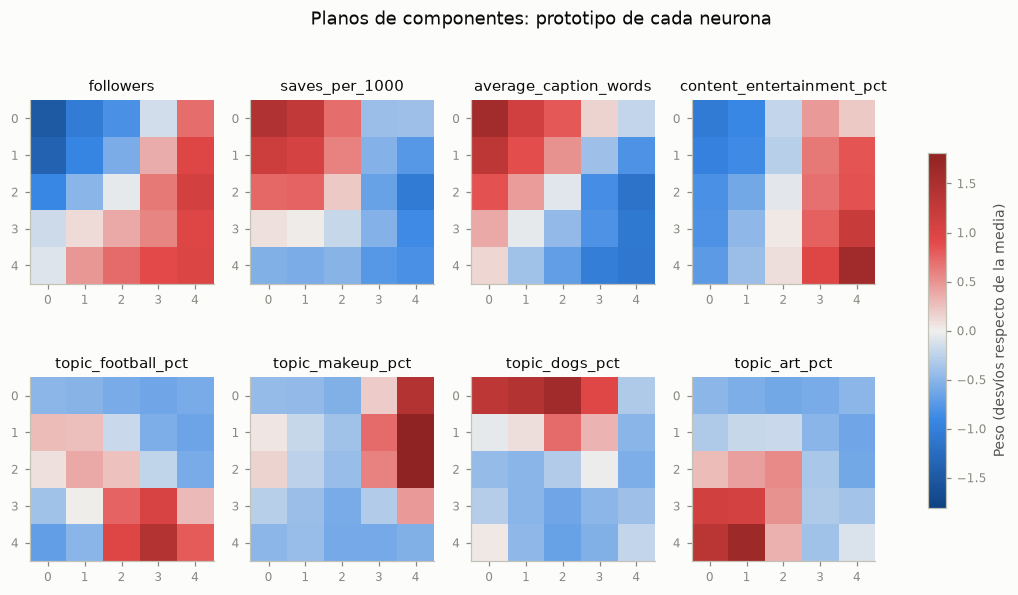

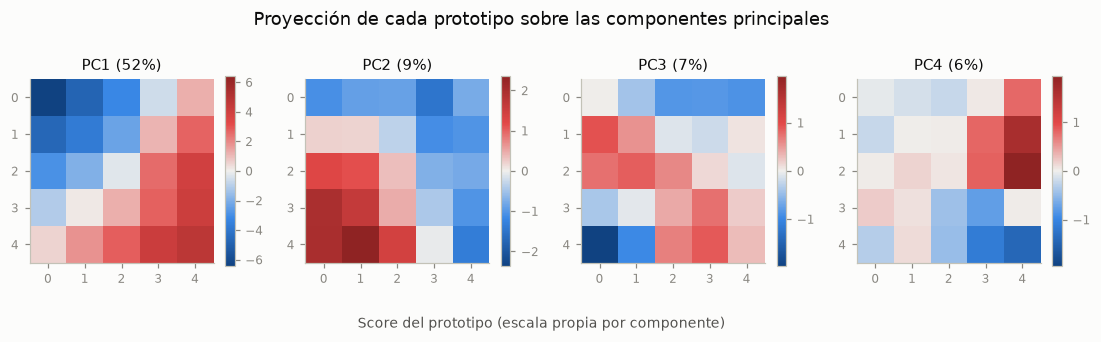

In [13]:
selected = ["followers", "saves_per_1000", "average_caption_words", "content_entertainment_pct",
            "topic_football_pct", "topic_makeup_pct", "topic_dogs_pct", "topic_art_pct"]
weights = som.weights_.reshape(som.rows, som.cols, -1)
plots.plot_planes(weights[:, :, [features.index(v) for v in selected]], selected,
                  "Planos de componentes: prototipo de cada neurona", "Peso (desvíos respecto de la media)")
plt.show()

prototype_scores = pca.transform(som.weights_)[:, :4].reshape(som.rows, som.cols, 4)
plots.plot_planes(prototype_scores, [f"PC{k + 1} ({explained[k]:.0%})" for k in range(4)],
                  "Proyección de cada prototipo sobre las componentes principales",
                  "Score del prototipo (escala propia por componente)", shared_scale=False)
plt.show()

A partir de los planos se delimitan cinco regiones contiguas de la grilla. Para cada una se resume el perfil en unidades originales (mediana de los creadores asignados):

In [14]:
REGIONS = {
    "Perros: comunidad y profundidad": [(0, 0), (0, 1), (0, 2), (0, 3)],
    "Nicho profundo (fútbol y mixto)": [(1, 0), (1, 1), (2, 0), (2, 1)],
    "Arte: mostrar y reseñar": [(2, 2), (3, 0), (4, 0), (4, 1)],
    "Maquillaje masivo": [(0, 4), (1, 4), (2, 4)],
    "Masivo y descubrimiento": [(2, 3), (3, 2), (3, 3), (4, 2), (4, 3), (4, 4)],
}
cell_of = {tuple(int(v) for v in som.positions_[n]): n for n in range(som.n_neurons)}
neuron_region = {cell_of[cell]: name for name, cells in REGIONS.items() for cell in cells}
winners = som.predict(X)
region = pd.Series([neuron_region.get(n, "sin región") for n in winners], name="región")
assert (region != "sin región").all()

profile_columns = ["followers", "price_usd", "non_follower_reach_pct", "saves_per_1000",
                   "profile_visits_per_1000", "average_caption_words", "content_entertainment_pct",
                   "argentina_audience_pct", "sponsored_posts_pct"]
profiles = df[profile_columns].groupby(region).median()
profiles.insert(0, "creadores", region.value_counts())
profiles.insert(1, "temáticas", data.topic.groupby(region).agg(
    lambda s: ", ".join(f"{t} {n}" for t, n in s.value_counts().items())))
profiles["PC1 medio"] = pd.Series(scores[:, 0]).groupby(region).mean()
profiles["PC2 medio"] = pd.Series(scores[:, 1]).groupby(region).mean()
display(profiles.loc[list(REGIONS)])

,creadores,temáticas,followers,price_usd,non_follower_reach_pct,saves_per_1000,profile_visits_per_1000,average_caption_words,content_entertainment_pct,argentina_audience_pct,sponsored_posts_pct,PC1 medio,PC2 medio
región,,,,,,,,,,,,,
Perros: comunidad y profundidad,10,Perros 10,"34,080.000",203.970,39.030,19.835,22.425,159.020,3.980,68.745,10.225,-4.727,-1.302
Nicho profundo (fútbol y mixto),10,"Fútbol 6, Arte 2, Maquillaje 2","35,756.000",256.070,45.980,18.915,19.405,144.455,9.455,47.865,48.050,-3.146,0.961
Arte: mostrar y reseñar,8,"Arte 7, Perros 1","229,399.500","1,290.660",55.490,12.305,18.830,101.150,14.535,34.515,40.515,0.788,2.044
Maquillaje masivo,9,Maquillaje 9,"426,362.000","2,783.980",63.050,9.920,13.360,56.190,59.000,36.440,15.010,2.968,-0.740
Masivo y descubrimiento,13,"Fútbol 9, Perros 2, Arte 2","349,287.000","3,251.200",76.210,9.960,13.060,60.810,61.260,59.810,39.020,3.516,-0.483


### ¿Qué perfiles reúne cada región?

| Región | Perfil |
|---|---|
| **Perros: comunidad y profundidad** (fila superior) | Los creadores más chicos y baratos, con mayor audiencia argentina, textos largos, tutoriales y la mayor tasa de guardados y visitas al perfil. Es el polo "profundo" de PC1. |
| **Nicho profundo** (arriba a la izquierda, debajo de perros) | Creadores chicos de fútbol, con algunos de maquillaje y arte: alta interacción de intención y más contenido patrocinado. |
| **Arte: mostrar y reseñar** (abajo a la izquierda) | Contenido que muestra resultados y reseña materiales, de tamaño intermedio. Es el polo positivo de PC2. |
| **Maquillaje masivo** (columna derecha) | Maquillaje con muchos seguidores, entretenimiento y videos cortos, y pocos guardados y comentarios. |
| **Masivo y descubrimiento** (abajo a la derecha) | Los creadores más grandes y caros, con alto alcance a no seguidores y contenido de entretenimiento. Es mayoritariamente fútbol, pero también reúne perros y arte: **a esta escala la temática pesa menos que el tamaño**. |

### ¿Coinciden con PC1 y PC2?

Sí. El plano de **PC1** crece en diagonal, de la esquina superior izquierda (perros profundos, PC1 ≈ −6) a la inferior derecha (masivos, PC1 ≈ +5): la red reproduce el eje masivo ↔ profundo sin haber recibido información del PCA. **PC2** crece hacia abajo a la izquierda (arte) y es mínimo en la fila de perros y en la columna derecha (maquillaje y entretenimiento), igual que en el biplot.

El mapa además separa perfiles que en el plano PC1–PC2 se superponen: **maquillaje** (alto en PC4) queda aislado en la columna derecha, y **fútbol** (alto en PC3) se separa de perros y de arte. Una grilla 2D no lineal resume información que en el PCA está repartida en ≈ 4 componentes: 72 % de varianza explicada contra 61 % del plano PC1–PC2.

### ¿Qué indica una distancia alta en la matriz U?

Una frontera entre perfiles (sección 8). Para la agencia, elegir un creador del otro lado de una frontera alta es cambiar de audiencia y de contenido, aunque en la grilla estén cerca. Dentro de una zona de U baja, los creadores son reemplazos razonables entre sí.

## 10. Conclusiones del 1.2

- **Modelo:** grilla 5×5, $\eta_0 = 0{,}5$, $R_0 = 2{,}5 \rightarrow 0{,}5$, 100 épocas. Explica ≈ 72 % de la varianza con error topográfico nulo y es estable entre semillas.
- **Estructura:** el mapa reproduce el eje masivo ↔ profundo en diagonal y separa las temáticas en cinco regiones. No hay grupos aislados, sino un continuo con fronteras moderadas.
- **Para las campañas:** cada cliente tiene su región de candidatos. Elegir sólo por seguidores lleva siempre a la región masiva, sea cual sea el cliente.

## 11. Implementación y convergencia

`oja.Oja` es una neurona lineal, $y = w^\top x$, entrenada online sobre las mismas 27 variables estandarizadas con la regla de Oja:
$$\Delta w = \eta\, y\,(x - y\,w)$$
El primer término ($\eta\, y\, x$) es aprendizaje hebbiano: refuerza los pesos en la dirección en que los datos varían. El segundo ($-\eta\, y^2 w$) evita que los pesos crezcan sin límite. El resultado es que $w$ converge al **autovector de norma 1 de mayor autovalor** de la matriz de correlación, es decir, a PC1, sin calcular esa matriz. Los pesos arrancan en un vector aleatorio de norma 1.

El único hiperparámetro relevante es la tasa de aprendizaje $\eta$. Se prueban varias con 5 semillas y 200 épocas:

,diverge,"|cos(w, PC1)|",‖w‖,"épocas hasta |cos| > 0,999"
η,,,,
0.0001,0,1.000,1.000,68.800
0.001,0,1.000,1.003,7.400
0.01,0,0.977,1.034,NaN
0.03,0,0.872,1.127,NaN
0.05,5,NaN,NaN,NaN


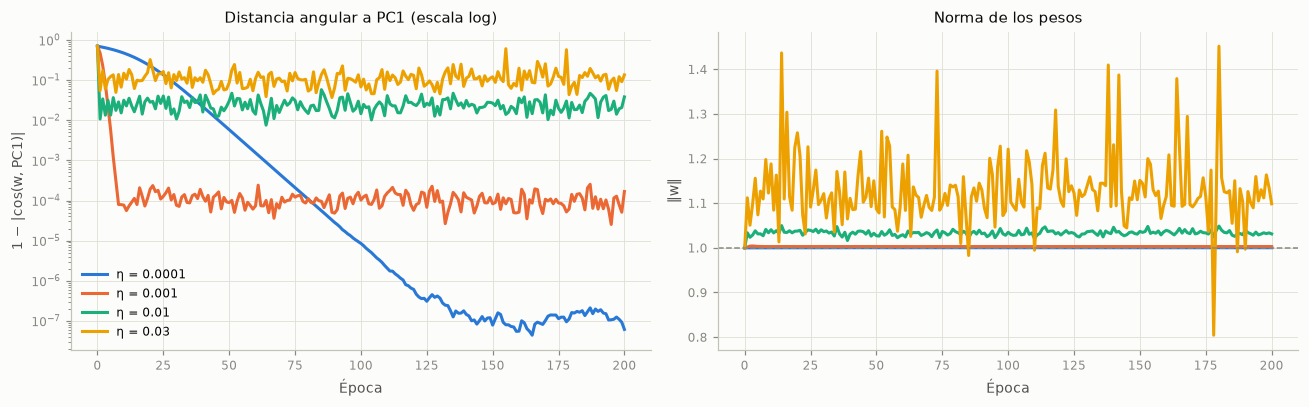

In [15]:
from oja import Oja, alignment, orient

pc1_vector = pca.components_[0]
oja_rows, oja_histories = [], {}
for learning_rate in (1e-4, 1e-3, 1e-2, 3e-2, 5e-2):
    for seed in range(5):
        model = Oja(learning_rate=learning_rate, epochs=200, seed=seed).fit(X)
        if seed == 0 and not model.diverged_:
            oja_histories[f"η = {learning_rate:g}"] = model.history_
        oja_rows.append({
            "η": f"{learning_rate:g}",
            "diverge": model.diverged_,
            "|cos(w, PC1)|": np.nan if model.diverged_ else alignment(model.weights_[None], pc1_vector)[0],
            "‖w‖": np.nan if model.diverged_ else np.linalg.norm(model.weights_),
            "épocas hasta |cos| > 0,999": np.nan if model.diverged_ else
                (np.argmax(alignment(model.history_, pc1_vector) > 0.999)
                 if (alignment(model.history_, pc1_vector) > 0.999).any() else np.nan),
        })
display(pd.DataFrame(oja_rows).groupby("η", sort=False).agg(
    {"diverge": "sum", "|cos(w, PC1)|": "mean", "‖w‖": "mean", "épocas hasta |cos| > 0,999": "mean"}))
plots.plot_oja_convergence(oja_histories, pc1_vector)
plt.show()

- **η = 10⁻⁴:** converge con precisión ($|\cos| = 1{,}0000$), pero lento: necesita ≈ 70 épocas para llegar a 0,999.
- **η = 10⁻³:** llega a 0,999 en ≈ 7 épocas y se mantiene en $|\cos| \approx 0{,}9999$, con $\lVert w \rVert \approx 1$.
- **η = 10⁻² y 3·10⁻²:** se acercan a PC1 rápido pero no se estabilizan. Cada actualización mueve demasiado a $w$, que oscila alrededor de PC1 ($|\cos| \approx 0{,}98$ y $0{,}87$) con norma mayor que 1.
- **η = 5·10⁻²:** diverge en todas las semillas. La actualización se vuelve inestable cuando $\eta \lVert x \rVert^2$ es del orden de 2, y algunos creadores tienen $\lVert x \rVert^2 \approx 70$.

Se usa **η = 10⁻³ con 200 épocas**. El resultado es el mismo con cualquier semilla, salvo el signo, que es arbitrario: $w$ y $-w$ son igualmente válidos. Para comparar con PCA se orienta $w$ en el mismo sentido que PC1, con valores altos del lado masivo.

## 12. Comparación con PC1

|cos(w, PC1)| = 0.999832 | ‖w‖ = 1.0029
Varianza del índice = 14.227 | λ1 del PCA = 14.149
Correlación de Spearman entre rankings Oja y PC1 = 0.9999


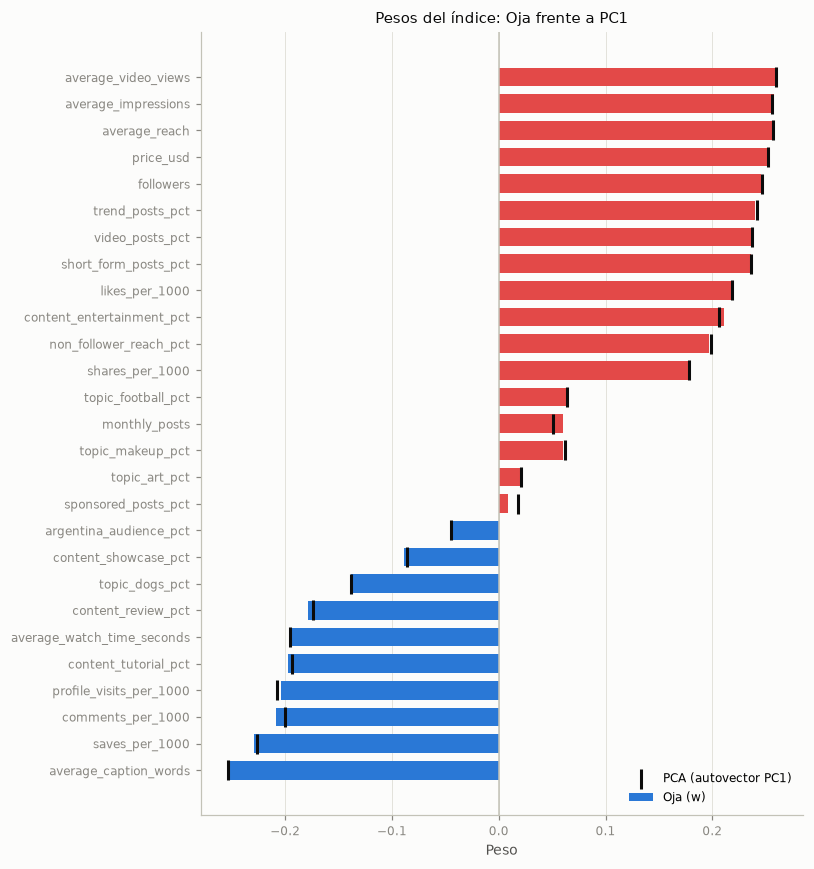

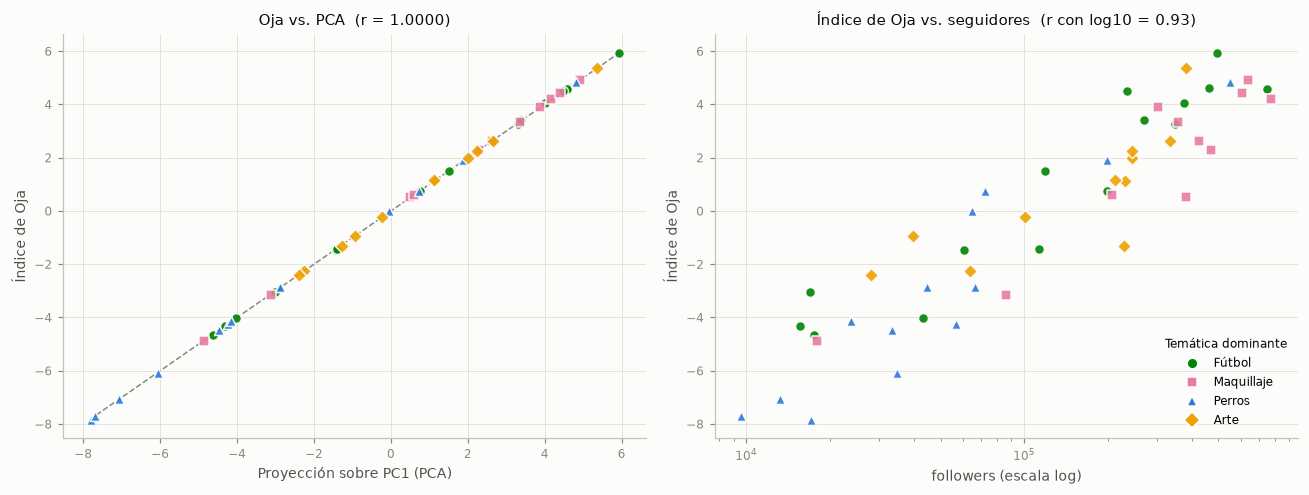

In [16]:
oja = Oja(learning_rate=1e-3, epochs=200, seed=0).fit(X)
oja_weights = orient(oja.weights_, pc1_vector)
oja_index = X @ oja_weights
pc1_scores = scores[:, 0]

from scipy.stats import spearmanr

print(f"|cos(w, PC1)| = {alignment(oja_weights[None], pc1_vector)[0]:.6f} | ‖w‖ = {np.linalg.norm(oja_weights):.4f}")
print(f"Varianza del índice = {oja_index.var():.3f} | λ1 del PCA = {eigenvalues[0]:.3f}")
print(f"Correlación de Spearman entre rankings Oja y PC1 = {spearmanr(oja_index, pc1_scores).statistic:.4f}")

plots.plot_oja_weights(oja_weights, pc1_vector, features)
plt.show()
plots.plot_index_comparison(oja_index, pc1_scores, df["followers"], data.topic)
plt.show()

La regla de Oja recupera PC1 sin construir la matriz de correlación ni calcular autovectores:

- **Pesos:** coinciden con el autovector de PC1 variable por variable ($|\cos| \approx 0{,}9999$). La varianza del índice es ≈ $\lambda_1$, la máxima que puede capturar una sola dirección.
- **Índice:** es prácticamente la proyección sobre PC1 (r ≈ 1) y ordena a los creadores igual (Spearman ≈ 1). Las pequeñas diferencias vienen de que con η constante $w$ oscila apenas alrededor de PC1. Se pueden reducir con una η decreciente o más pequeña.

## 13. Interpretación del índice

In [17]:
ranking = pd.DataFrame({
    "name": data.names, "temática": data.topic, "región Kohonen": region,
    "índice Oja": oja_index, "followers": df["followers"], "price_usd": df["price_usd"],
    "saves_per_1000": df["saves_per_1000"], "profile_visits_per_1000": df["profile_visits_per_1000"],
}).sort_values("índice Oja", ascending=False)
display(pd.concat([ranking.head(10), ranking.tail(5)]))

top_index = set(ranking.head(10)["name"])
top_followers = set(df.nlargest(10, "followers")["name"])
print(f"Temáticas del top 10 del índice: {ranking.head(10)['temática'].value_counts().to_dict()}")
print(f"Creadores en común entre el top 10 por índice y el top 10 por followers: {len(top_index & top_followers)}/10")

,name,temática,región Kohonen,índice Oja,followers,price_usd,saves_per_1000,profile_visits_per_1000
44,@futbolsinvueltas,Fútbol,Masivo y descubrimiento,5.949,493194,"4,655.310",5.160,15.480
39,@galeriacotidiana,Arte,Masivo y descubrimiento,5.379,381324,"4,866.570",9.420,9.040
1,@brillourbano,Maquillaje,Maquillaje masivo,4.927,638718,"6,334.710",7.910,9.360
35,@crearenreels,Perros,Masivo y descubrimiento,4.835,551553,"3,813.640",8.450,14.300
4,@tribunacreativa,Fútbol,Masivo y descubrimiento,4.602,461892,"2,806.200",9.960,11.920
20,@golconmate,Fútbol,Masivo y descubrimiento,4.580,745025,"3,251.200",5.900,10.690
33,@makeupconsejos,Fútbol,Masivo y descubrimiento,4.487,234076,"4,694.620",9.520,7.190
9,@maquillajereal,Maquillaje,Maquillaje masivo,4.418,608003,"2,946.880",5.990,7.050
0,@mateconideas,Maquillaje,Maquillaje masivo,4.192,775589,"6,310.690",4.300,16.360
10,@vidaperruna,Fútbol,Masivo y descubrimiento,4.042,374949,"3,300.620",10.860,11.440


Temáticas del top 10 del índice: {'Fútbol': 5, 'Maquillaje': 3, 'Arte': 1, 'Perros': 1}
Creadores en común entre el top 10 por índice y el top 10 por followers: 7/10


### ¿Qué representa el índice y cómo se interpreta?

Es la **posición de cada creador sobre el eje de máxima varianza** del catálogo, el mismo eje masivo ↔ profundo de PC1. Los pesos más altos y positivos son las variables de tamaño y precio (reach, views, impressions, followers, price_usd), formato corto, tendencias y entretenimiento. Los más negativos son palabras del texto, guardados, visitas al perfil, comentarios, tiempo de reproducción y tutoriales.

- **Índice alto:** creador grande, caro, de contenido breve y de entretenimiento, con mucho alcance a no seguidores y reacciones rápidas (likes, shares). Perfil de **descubrimiento masivo**.
- **Índice bajo:** creador chico, barato, de contenido largo y educativo, con audiencia que guarda, comenta y visita el perfil. Perfil de **comunidad y profundidad**.
- **Índice cercano a 0:** perfil intermedio.

Es un resumen **descriptivo**, no una medida de calidad: dice "qué tan masivo vs. profundo es el creador", no "qué tan bueno es". Su correlación con log10(followers) es ≈ 0,93: ordena casi igual que la cantidad de seguidores (7 de los 10 primeros coinciden).

### ¿Sería correcto elegir automáticamente al creador con el valor más alto para cualquier campaña?

**No.**

1. **El signo es arbitrario.** Oja converge a $w$ o a $-w$ según la inicialización. "Más alto" es "más masivo" sólo porque se eligió esa orientación. Con la opuesta, el máximo sería el creador más profundo.
2. **No contiene el objetivo de la campaña.** El índice se aprendió sin saber qué vende cada cliente. El top 10 mezcla fútbol, maquillaje, arte y perros: un refugio de perros terminaría con un creador de fútbol.
3. **Ignora la temática.** La temática, que es lo que define a qué cliente le sirve un creador, está en PC2–PC4. Una sola dirección retiene 52 % de la varianza y descarta justamente esa información.
4. **Premia lo que la agencia ya hace mal.** Maximizar el índice es casi lo mismo que maximizar followers: los más caros y con menor engagement de intención (guardados, visitas al perfil). Es la estrategia que hoy no recupera la inversión.
5. **Depende de la selección de variables.** El bloque de tamaño pesa de más (conclusiones del 1.1). Con otra selección de variables, el índice cambiaría.

El índice sirve como **una dimensión más para filtrar**, por ejemplo para elegir entre creadores de la temática correcta según si la campaña busca alcance (índice alto) o profundidad (índice bajo). No sirve como ranking único.

## 14. Conclusiones del 1.3

- **Oja recupera PC1:** con η = 10⁻³, el índice ordena a los creadores igual que la proyección sobre PC1 (Spearman ≈ 1), sin calcular la matriz de correlación.
- **No es un ranking de calidad:** mide qué tan masivo o profundo es un creador. Sirve para elegir dentro de la temática correcta, no para elegir el máximo en cualquier campaña.

## 15. Supuestos y métrica de campaña

Cada método cumple un papel distinto en la decisión:

| Paso | Método | Qué aporta |
|---|---|---|
| Describir el catálogo | PCA (1.1) | Las variables a usar y los dos tipos de estructura: tamaño y temática. |
| Armar los candidatos | Kohonen (1.2) | La región de la grilla que corresponde a cada cliente. |
| Ubicar el tipo de alcance | Oja (1.3) | Si cada candidato es masivo, intermedio o profundo. |
| Elegir | Costo por intención (supuestos de esta sección) | El orden dentro de los candidatos. |

Los métodos no supervisados describen a los creadores, pero no saben qué necesita cada cliente. Para el último paso hace falta traducir el objetivo de la campaña a una métrica.

`campaigns.py` usa estos supuestos:

- **Audiencia útil:** los clientes operan en Argentina, así que cuenta el alcance estimado en Argentina (`estimated_argentina_reach`). Para un refugio, que necesita adoptantes cerca, esto es aún más importante.
- **Interés en el rubro:** la fracción de esa audiencia interesada es proporcional al porcentaje de publicaciones del creador sobre la temática del cliente.
- **Intención:** guardados, comentarios y visitas al perfil indican que la persona quiere volver, preguntar o conocer más, que es el paso previo a una compra o una consulta de adopción. Likes y compartidos son reacciones rápidas y no se cuentan.

Con eso, por publicación patrocinada:
$$\text{alcance relevante} = \text{alcance en Argentina} \times \%\text{temática}, \qquad \text{intención relevante} = \text{alcance relevante} \times \frac{\text{guardados} + \text{comentarios} + \text{visitas}}{1000}$$

Los cuatro clientes buscan acciones (adopciones o ventas), así que la métrica a minimizar es el **costo por interacción de intención relevante** (USD / intención relevante).

## 16. Campaña de fútbol

¿Conviene priorizar alcance masivo, descubrimiento o profundidad educativa? Los 15 creadores de fútbol se separan en tres perfiles según el índice de Oja (PC1), y se comparan sus medianas:

In [18]:
import campaigns

football = data.topic == "Fútbol"
football_metrics = campaigns.campaign_metrics(df, "Fútbol")
football_profile = pd.cut(pd.Series(oja_index)[football], [-np.inf, -1, 2, np.inf],
                          labels=["profundo (índice < −1)", "intermedio", "masivo (índice > 2)"])
football_table = df.loc[football].assign(
    cpm=df["price_usd"] / df["average_reach"] * 1000,
    intención_por_1000=df["saves_per_1000"] + df["comments_per_1000"] + df["profile_visits_per_1000"],
    usd_por_intención=football_metrics[campaigns.OBJECTIVES["intención"]],
)
summary_columns = ["followers", "price_usd", "cpm", "intención_por_1000", "content_tutorial_pct",
                   "content_entertainment_pct", "average_watch_time_seconds", "non_follower_reach_pct",
                   "sponsored_posts_pct", "argentina_audience_pct", "topic_football_pct", "usd_por_intención"]
football_summary = football_table.groupby(football_profile, observed=True)[summary_columns].median().T
football_summary.loc["creadores"] = football_profile.value_counts()
display(football_summary)
display(football_table.assign(perfil=football_profile)
        .sort_values("usd_por_intención")[["name", "perfil", "argentina_audience_pct",
                                          "topic_football_pct", "usd_por_intención"]])

,profundo (índice < −1),intermedio,masivo (índice > 2)
followers,"30,406.000","158,347.500","374,949.000"
price_usd,284.345,"1,262.125","3,300.620"
cpm,22.480,18.453,25.595
intención_por_1000,45.760,33.580,22.540
content_tutorial_pct,42.050,28.015,8.250
content_entertainment_pct,9.455,40.225,61.260
average_watch_time_seconds,29.270,27.550,18.250
non_follower_reach_pct,53.270,71.780,76.210
sponsored_posts_pct,53.020,24.390,39.510
argentina_audience_pct,40.955,67.515,29.520


,name,perfil,argentina_audience_pct,topic_football_pct,usd_por_intención
8,@futbolcononda,intermedio,89.370,73.460,0.675
20,@golconmate,masivo (índice > 2),77.460,82.180,0.934
4,@tribunacreativa,masivo (índice > 2),68.300,61.100,1.490
29,@lookdecancha,masivo (índice > 2),77.760,69.290,1.498
40,@jugadayestilo,intermedio,45.660,79.190,1.878
26,@pasionalbirroja,profundo (índice < −1),40.290,70.980,1.987
36,@pasiondepotrero,profundo (índice < −1),52.330,49.880,2.159
32,@futbolentrepases,profundo (índice < −1),36.420,49.980,2.261
19,@manosalaobra,profundo (índice < −1),41.620,69.340,2.347
12,@canchaaldia,profundo (índice < −1),56.160,39.550,2.588


- **Profundidad educativa** (índice < −1): tiene la mejor tasa de intención (≈ 46 guardados, comentarios y visitas por cada 1000 cuentas), más tutoriales y más tiempo de reproducción. Pero sus creadores son chicos, sólo la mitad de su contenido es fútbol, menos de la mitad de su audiencia está en Argentina y más de la mitad de sus publicaciones ya son patrocinadas. Por cada dólar llegan a pocos hinchas argentinos.
- **Alcance masivo** (índice > 2): contenido de entretenimiento, mucho alcance a no seguidores, poca intención. Es un grupo heterogéneo. Algunos creadores tienen audiencia mayoritariamente argentina y son eficientes (0,9 a 1,5 USD por interacción relevante). Otros (@futbolsinvueltas, @tacticavisual, @vidaperruna, @makeupconsejos) tienen menos de 30 % de audiencia argentina, y cada interacción relevante cuesta entre 5 y 11 USD. (Los nombres de usuario del catálogo son sintéticos y no siempre coinciden con la temática: @vidaperruna y @makeupconsejos publican sobre fútbol.)
- **Descubrimiento** (intermedio): sólo dos creadores, pero con la mayor proporción de fútbol, mayoría de audiencia argentina, alto alcance a no seguidores y el menor costo por mil cuentas alcanzadas.

**Decisión: priorizar descubrimiento con audiencia argentina.** Los creadores más eficientes son @futbolcononda (intermedio, 89 % de audiencia argentina) y masivos con audiencia local como @golconmate y @tribunacreativa. Para vender ropa de entrenamiento en Argentina, lo que limita no es la profundidad del contenido sino llegar a hinchas argentinos que no siguen al creador. La profundidad educativa no compensa su audiencia chica y extranjera. El alcance masivo sólo sirve si es local: elegir "el más grande" sin mirar `argentina_audience_pct` lleva a los casos más caros.

Esto muestra un límite del índice de Oja (1.3): la audiencia argentina casi no pesa en PC1 (carga −0,17), así que el índice no la ve. Hay que mirarla aparte.

## 17. Selección propuesta frente a la selección por seguidores

Para cada cliente se eligen 3 creadores con tres estrategias:

1. **Top followers (actual):** los 3 con más seguidores del catálogo. Es lo que hace hoy la agencia, y da los mismos creadores para todos los clientes.
2. **Top followers de la temática:** una versión mejorada, con los 3 con más seguidores de la temática del cliente.
3. **Temática + costo por intención (propuesta):** de la temática del cliente, los 3 con menor costo por interacción de intención relevante.

creadores  \
cliente              estrategia                                                                             
Refugio de perros    Top followers (actual)                     @mateconideas, @golconmate, @brillourbano   
                     Top followers de la temática         @crearenreels, @patitasenred, @patitascontentas   
                     Temática + costo por intención    @huellasyconsejos, @consejoscaninos, @crearenreels   
Ropa de fútbol       Top followers (actual)                     @mateconideas, @golconmate, @brillourbano   
                     Top followers de la temática        @golconmate, @futbolsinvueltas, @tribunacreativa   
                     Temática + costo por intención         @futbolcononda, @golconmate, @tribunacreativa   
Productos de belleza Top followers (actual)                     @mateconideas, @golconmate, @brillourbano   
                     Top followers de la temática           @mateconideas, @brillourbano, @maquillajereal   
                     Temática + costo por intención        @reelargentino, @brochasymates, @brochasycolor   
Materiales de arte   Top followers (actual)                     @mateconideas, @golconmate, @brillourbano   
                     Top followers de la temática    @galeriacotidiana, @pincelcotidiano, @artequeinspira   
                     Temática + costo por intención  @rinconcreativo, @colorenmovimiento, @artequeinspira   

                                                                                             regiones Kohonen  \
cliente              estrategia                                                                                 
Refugio de perros    Top followers (actual)                        Maquillaje masivo, Masivo y descubrimiento   
                     Top followers de la temática            Arte: mostrar y reseñar, Masivo y descubrimiento   
                     Temática + costo por intención  Masivo y descubrimiento, Perros: comunidad y profundidad   
Ropa de fútbol       Top followers (actual)                        Maquillaje masivo, Masivo y descubrimiento   
                     Top followers de la temática                                     Masivo y descubrimiento   
                     Temática + costo por intención                                   Masivo y descubrimiento   
Productos de belleza Top followers (actual)                        Maquillaje masivo, Masivo y descubrimiento   
                     Top followers de la temática                                           Maquillaje masivo   
                     Temática + costo por intención        Maquillaje masivo, Nicho profundo (fútbol y mixto)   
Materiales de arte   Top followers (actual)                        Maquillaje masivo, Masivo y descubrimiento   
                     Top followers de la temática            Arte: mostrar y reseñar, Masivo y descubrimiento   
                     Temática + costo por intención          Arte: mostrar y reseñar, Masivo y descubrimiento   

                                                     de la temática  \
cliente              estrategia                                       
Refugio de perros    Top followers (actual)                       0   
                     Top followers de la temática                 3   
                     Temática + costo por intención               3   
Ropa de fútbol       Top followers (actual)                       1   
                     Top followers de la temática                 3   
                     Temática + costo por intención               3   
Productos de belleza Top followers (actual)                       2   
                     Top followers de la temática                 3   
                     Temática + costo por intención               3   
Materiales de arte   Top followers (actual)                       0   
                     Top followers de la temática                 3   
                     Temática + costo por intención            

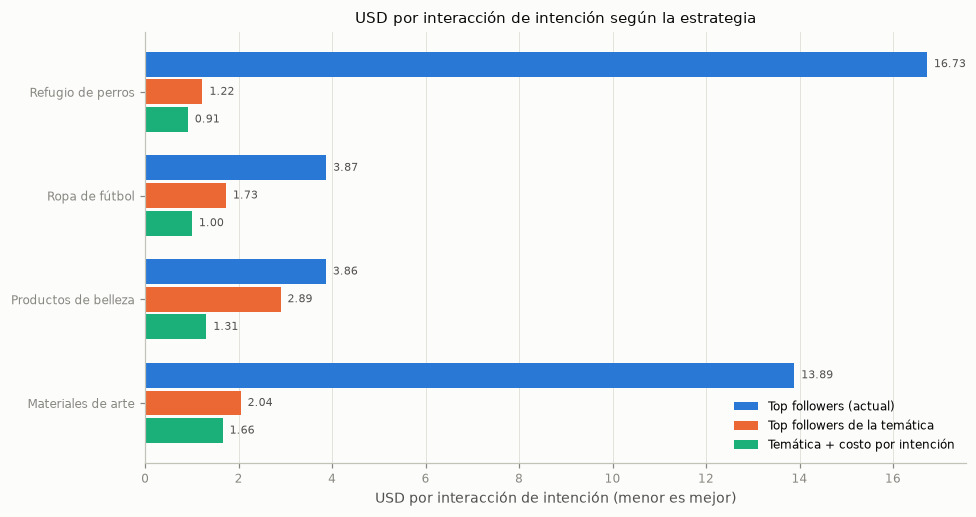

In [19]:
comparison = campaigns.compare_strategies(df, data.topic, pd.Series(oja_index))
region_of = dict(zip(data.names, region))
comparison.insert(1, "regiones Kohonen", comparison["creadores"].str.split(", ").map(
    lambda names: ", ".join(sorted({region_of[n] for n in names}))))
display(comparison)
plots.plot_strategy_comparison(comparison, campaigns.OBJECTIVES["intención"])
plt.show()

**Resultados**

- **Seleccionar sólo por seguidores** elige tres creadores masivos (dos de maquillaje y uno de fútbol) para todos los clientes. Para el refugio y para arte, **ninguno es de la temática**, y cada interacción relevante cuesta ≈ 17 USD (refugio) y ≈ 14 USD (arte), contra 0,9 y 1,7 USD de la propuesta. Además, la selección cuesta ≈ 15.900 USD por ronda de publicaciones.
- **Filtrar por temática** corrige lo peor, pero sigue pagando 1,2 a 2,2 veces más por interacción relevante que la propuesta. Elige a los más grandes, aunque tengan audiencia extranjera o engagement superficial.
- **La propuesta** obtiene el menor costo por intención en los cuatro clientes y cuesta menos en total. El índice de Oja medio de lo elegido muestra que **no hay un lado de PC1 que sirva para todos**:
  - el refugio y belleza terminan en el polo profundo (índice ≈ −3 y −2,5);
  - fútbol en el lado masivo con audiencia local (≈ +3,3);
  - arte en el medio (≈ +0,7).
- **Las regiones de Kohonen anticipan la selección.** La mayor parte de lo que elige la propuesta cae en la región de su cliente: dos de los tres creadores del refugio están en "Perros: comunidad y profundidad", dos de los tres de belleza en el nicho profundo, dos de los tres de arte en "Arte: mostrar y reseñar" y los tres de fútbol en "Masivo y descubrimiento". La selección por seguidores, en cambio, cae siempre en las regiones masivas ("Maquillaje masivo" y "Masivo y descubrimiento"), sea cual sea el cliente.

**Ventajas y desventajas**

| | Por seguidores | Propuesta |
|---|---|---|
| **Ventajas** | Simple y objetiva. Pocos contratos con gran alcance bruto. Útil para campañas de pura visibilidad de marca. | Respeta la temática del cliente. Mide la audiencia que importa (local, interesada, con intención). Más barata por resultado. Interpretable con las regiones de Kohonen y el índice. |
| **Desventajas** | Ignora temática, localización y tipo de engagement. Concentra el presupuesto en los creadores más caros. Mismo resultado para todos los clientes. | Depende de supuestos no validados: que el % de la temática refleje el interés y que la intención anticipe ventas o adopciones. Con creadores más chicos hay más contratos para gestionar. Algunos creadores profundos ya están saturados de publicidad. |

Ninguna de las dos se valida con los datos disponibles, porque no hay ventas ni adopciones medidas. Lo correcto es probar la propuesta en campañas reales y usar los resultados para ajustar la métrica.

## 18. Mantenimiento del sistema

**Llega una nueva campaña.** Si es de uno de los cuatro rubros, no hace falta reentrenar nada: se agrega una entrada en `campaigns.CLIENTS` con la temática y el objetivo (`"intención"` para ventas o adopciones, `"alcance"` para visibilidad). Si es de un rubro nuevo, por ejemplo tecnología, no hay ninguna variable que lo represente: hay que relevar el porcentaje de contenido de ese tema para todos los creadores, y eso implica agregar variables (ver abajo).

**Cambia la cantidad de creadores.**
- **Pocos creadores nuevos:** se transforman con la misma estandarización (`Standardizer` ya ajustado), se proyectan sobre PC1 o sobre $w$ de Oja para obtener su índice, y se asignan a su neurona ganadora en el mapa, todo sin reentrenar. Conviene controlar su error de cuantización: si es mucho mayor que el del resto, el mapa no tiene un prototipo para ese perfil.
- **Muchos creadores nuevos o perfiles nuevos:** hay que reentrenar todo (estandarización, PCA, barrido de Kohonen y Oja). La grilla puede necesitar otro tamaño, y el mapa puede quedar rotado o espejado. Las regiones del 1.2 están definidas a mano (`REGIONS`), así que habría que volver a delimitarlas o automatizar su asignación, por ejemplo por la temática dominante y el índice de cada prototipo.

**Se incorporan variables nuevas.** Cambia la dimensión de entrada, así que se reentrenan todos los modelos. Antes hay que repetir el EDA: detectar derivadas y redundancias, y decidir transformaciones. Cada variable redundante suma peso a su bloque en PC1, en el índice y en la distancia de Kohonen, así que el significado del índice puede cambiar.

**Actualización mensual de los datos.** Las variables son promedios mensuales, así que los creadores se mueven de un mes a otro.
- Si la estandarización se reajusta cada mes, cambia la escala y los índices dejan de ser comparables entre meses. Conviene fijar una estandarización de referencia y reajustarla periódicamente.
- Ambos métodos pueden actualizarse **de forma incremental**: Oja es una regla online, y Kohonen puede seguir entrenando desde los pesos anteriores con $\eta$ y radio chicos. Así se conservan la orientación del índice y la ubicación de las regiones, y se puede seguir qué creadores cambian de región.
- Usar `price_usd` y no `price_ars` evita que la variación del tipo de cambio aparezca como un cambio en los creadores.
- Con 50 creadores, reentrenar todo lleva segundos. El costo real del mantenimiento está en revisar la interpretación (regiones y signo del índice), no en el cómputo.

## 19. Conclusiones generales

- **La hipótesis se confirma.** El catálogo tiene un eje dominante, masivo ↔ profundo (PC1, 52 %), que es casi el log de los seguidores, y la temática en otras direcciones (PC2–PC4). Kohonen reproduce ambas en un mapa 2D y Oja recupera PC1 como índice.
- **Fútbol:** conviene priorizar el descubrimiento con audiencia argentina. La profundidad educativa no compensa una audiencia chica y extranjera, y lo masivo sólo sirve si es local.
- **Seguidores frente a la propuesta:** elegir por seguidores es elegir por PC1. Ignora la temática y la audiencia local, y paga de 8 a 18 veces más por interacción relevante cuando no elige ningún creador del rubro. La propuesta tiene el menor costo en los cuatro clientes, pero depende de supuestos que hay que validar con campañas reales.
- **Mantenimiento:** una campaña nueva de un rubro conocido no requiere reentrenar; un rubro o variables nuevas sí. Lo costoso no es el cómputo sino revisar la interpretación (regiones y signo del índice).